# TMAP analysis

## Imports

In [1]:
from amp import load, work_in_outputs
work_in_outputs("06_tmap")
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['svg.fonttype'] = 'none'

import numpy as np

from rdkit import Chem
from rdkit.Chem import AllChem

import tmap
from faerun import Faerun
from rdkit.Chem import AllChem

In [2]:
# Import antibacterial data
df_ab = load("antibacterial_assays")

# import feature
df_features = load("molecular_features")

# Clean
df_features.drop_duplicates(subset = ['ID'],inplace=True)
df_features.set_index('ID',inplace=True)

df_features['Scaffold'] = [x.strip() for x in df_features['Scaffold']]
df_features['Scaffold'].unique()

df_features['Scaffold'] = df_features['Scaffold'].astype('category')


## Categories of antibacterial activity

In [3]:

# Add class column and populate accordingly to pMIC and LogDD data
df_ab['class'] = 0
df_ab.loc[df_ab['logMIC'] > 1,'class'] = 1
df_ab.loc[df_ab['logDD'] < 3,'class'] = 1
df_ab.loc[(df_ab['logMIC'] <= 1) & (df_ab['logMIC'] > 0),'class'] = 2
df_ab.loc[(df_ab['logDD'] >= 3) & (df_ab['logDD'] < 4),'class'] = 2
df_ab.loc[df_ab['logMIC'] <= 0,'class'] = 3
df_ab.loc[df_ab['logDD'] >= 4,'class'] = 3


In [4]:

class_id = df_ab[['ID','class']].groupby(by=['ID']).mean()
print(f'number of compounds: {class_id.shape[0]}')

class_count = pd.DataFrame.from_dict({
    'na' : class_id[class_id['class'] == 0].value_counts().sum(),
    'np' : class_id[(class_id['class'] > 0) & (class_id['class'] < 1)].value_counts().sum(),
    'p' : class_id[(class_id['class'] >= 1) & (class_id['class'] < 2)].value_counts().sum(),
    'vp' : class_id[(class_id['class'] >= 2) & (class_id['class'] <= 3)].value_counts().sum(),
},orient='index')

number of compounds: 246


In [5]:
class_count

,0
na,94
np,57
p,65
vp,30


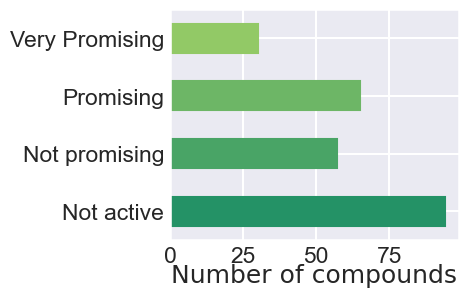

In [6]:
# plot 
sns.set_context("talk")
sns.set_style("darkgrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }
colors = sns.color_palette("summer")[0:4]

f, ax = plt.subplots(figsize=(4, 3))
bar = class_count.plot.barh(ax=ax, colormap = "summer")

ax.set_box_aspect(0.8)
ax.tick_params(axis='both', which='major', pad=-5)

ax.set_yticklabels(['Not active', 'Not promising','Promising','Very Promising'])
ax.set_xlabel("Number of compounds", fontdict=font,labelpad=-2)
ax.get_legend().remove()

for i in range(0,len(class_count)):
    ax.get_children()[i].set_color(colors[i])

plt.savefig('plots/bar_assays-scaffold.svg')

In [7]:
# Create categories
class_id['category'] = 0
class_id.loc[(class_id['class'] > 0) & (class_id['class'] < 1),'category'] = 1
class_id.loc[(class_id['class'] >= 1) & (class_id['class'] < 2),'category'] = 2
class_id.loc[(class_id['class'] >= 2) & (class_id['class'] <= 3),'category'] = 3

## Formating TMAP

In [8]:
# add SMILES
class_id = pd.concat([class_id, df_features['SMILES']], axis=1)

# create smiles for TMAP labels
class_id["smiles_labels"] = (
        class_id["SMILES"]
        + '__<a '
        + class_id.index
        + '">'
        + class_id.index
        + "</a>"
    )

In [9]:
class_id = pd.concat([class_id, df_features['Scaffold']], axis=1)

class_id['Scaffold_labels'] = 0
class_id.loc[class_id['Scaffold'] == "benzophenone",'Scaffold_labels'] = 1
class_id.loc[class_id['Scaffold'] == "diphenyl-ether",'Scaffold_labels'] = 2
class_id.loc[class_id['Scaffold'] == "xanthone",'Scaffold_labels'] = 3

## TMAP

In [10]:
bits = 2048

mols = [Chem.MolFromSmiles(s) for s in class_id['SMILES']]
ECFP4_fps = [AllChem.GetMorganFingerprintAsBitVect(x,2,bits) for x in mols]
ecfp4_lists = [tmap.VectorUchar(list(fp)) for fp in ECFP4_fps]

In [11]:
# Initialize the Minhash
enc = tmap.Minhash(bits)

# Initialize the LSH Forest
lf_ecfp4 = tmap.LSHForest(bits)

# Add the Fingerprints to the LSH Forest and index
lf_ecfp4.batch_add(enc.batch_from_binary_array(ecfp4_lists))
lf_ecfp4.index()

In [12]:
x, y, s, t, _ = tmap.layout_from_lsh_forest(lf_ecfp4)

In [13]:
# Plot the data
faerun = Faerun(view="front", coords=False)
faerun.add_scatter(
    "ECFP4",
    {   "x": x, 
        "y": y, 
        "c": class_id.category, 
        "labels": class_id["smiles_labels"]},
    point_scale=8,
    colormap = ['summer'],
    has_legend=True,
    legend_title = ['Category'],
    categorical=[False],
    selected_labels=["SMILES", "Name"],
    legend_labels=[(0,'Not active'), (1,'Not promising'),(2,'Promising'),(3,'Very Promising')],
    shader = 'smoothCircle'
)

faerun.add_tree("ECFP4_tree", {"from": s, "to": t}, point_helper="ECFP4")

# Choose the "smiles" template to display structure on hover
faerun.plot('schemes/TMAP_category', template="smiles" , notebook_height=750)

outputs/06_tmap/schemes/TMAP_category.html

In [14]:
# Plot the data
faerun = Faerun(view="front", coords=False)
faerun.add_scatter(
    "ECFP4",
    {   "x": x, 
        "y": y, 
        "c": class_id.Scaffold_labels, 
        "labels": class_id["smiles_labels"]},
    point_scale=8,
    colormap = ['tab10'],
    has_legend=True,
    legend_title = ['Category'],
    categorical=[True],
    selected_labels=["SMILES", "Name"],
    legend_labels=[(0,'Anthraquinone'), (1,'Benzophenone'),(2,'Diphenyl ether'),(3,'Xanthone')],
    shader = 'smoothCircle'
)

faerun.add_tree("ECFP4_tree", {"from": s, "to": t}, point_helper="ECFP4")

# Choose the "smiles" template to display structure on hover
faerun.plot('schemes/TMAP_scaffold', template="smiles" , notebook_height=750)

outputs/06_tmap/schemes/TMAP_scaffold.html

## Clustering to analyze very promising

In [15]:
# calculate fp from SMILES
fps = []
fp_bitvect = []
for smiles in class_id.loc[class_id['category'] == 3,'SMILES']:
	mol = Chem.MolFromSmiles(smiles)
	fp = AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=16392)
	fp_bitvect.append(fp)
	fp_array = np.asarray(fp)
	fps.append(fp_array)

print("Number of compounds converted:", len(fps))
print("Fingerprint length per compound:", len(fps[0]))

Number of compounds converted: 30
Fingerprint length per compound: 16392


In [16]:
from rdkit import Chem
from rdkit.Chem import AllChem

from rdkit import DataStructs
from rdkit.ML.Cluster import Butina

from rdkit.Chem import Draw
from rdkit.Chem.Draw import DrawingOptions
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')
from rdkit.Chem.Draw import SimilarityMaps

DrawingOptions.atomLabelFontSize = 55
DrawingOptions.dotsPerAngstrom = 100
DrawingOptions.bondLineWidth=3.0

In [17]:
def tanimoto_distance_matrix(fp_list):
    """Calculate distance matrix for fingerprint list"""
    dissimilarity_matrix = []
    # Notice how we are deliberately skipping the first and last items in the list
    # because we don't need to compare them against themselves
    for i in range(1, len(fp_list)):
        # Compare the current fingerprint against all the previous ones in the list
        similarities = DataStructs.BulkTanimotoSimilarity(fp_list[i], fp_list[:i])
        # Since we need a distance matrix, calculate 1-x for every element in similarity matrix
        dissimilarity_matrix.extend([1 - x for x in similarities])
    return dissimilarity_matrix

def cluster_fingerprints(fingerprints, cutoff=0.2):
    """Cluster fingerprints
    Parameters:
        fingerprints
        cutoff: threshold for the clustering
    """
    # Calculate Tanimoto distance matrix
    distance_matrix = tanimoto_distance_matrix(fingerprints)
    # Now cluster the data with the implemented Butina algorithm:
    clusters = Butina.ClusterData(distance_matrix, len(fingerprints), cutoff, isDistData=True)
    clusters = sorted(clusters, key=len, reverse=True)
    return clusters

In [18]:
# Set cutoff for a 1/3 of similiarty
clusters = cluster_fingerprints(fp_bitvect, cutoff=0.8)
clusters

[(15, 13, 14, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28),
 (1, 0, 2, 4, 7, 8, 9, 10, 11, 29),
 (6, 5),
 (3,),
 (12,)]

## Draw very promising molecules

In [19]:
class_id[class_id['category'] == 3].index

Index(['AQ030', 'AQ042', 'AQ052', 'AQ055', 'AQ080', 'AQ132', 'AQ134', 'AQ140',
       'AQ141', 'AQ145', 'AQ146', 'AQ147', 'BZ014', 'DP027', 'DP030', 'DP031',
       'DP039', 'DP040', 'DP041', 'DP043', 'DP047', 'DP049', 'DP056', 'DP061',
       'DP062', 'DP064', 'DP065', 'DP067', 'DP088', 'XT241'],
      dtype='object', name='ID')

In [20]:
class_id['mol'] = class_id['SMILES'].apply(Chem.MolFromSmiles)
# Draw  
Draw.MolsToGridImage(class_id.loc[class_id['category'] == 3,'mol'],molsPerRow=5, useSVG=True, legends=list(class_id.index[class_id['category'] == 3]))

# Save grid
grid = Draw.MolsToGridImage(class_id.loc[class_id['category'] == 3,'mol'],molsPerRow=5, useSVG=True, legends=list(class_id.index[class_id['category'] == 3]))
with open('grid.svg', 'w') as f:
    f.write(grid.data)

## Analysis of very promising compounds

In [21]:
df_features.loc[['AQ042',  'AQ080', 'AQ030', 'AQ132'],['MolWt','Mean Log P','FractionCSP3', 'NumRotatableBonds', 'TPSA', 'Mean Log S']]

,MolWt,Mean Log P,FractionCSP3,NumRotatableBonds,TPSA,Mean Log S
ID,,,,,,
AQ042,284.267,2.236703,0.125000,1.0,83.83,-4.170
AQ080,296.278,2.240703,0.117647,1.0,91.67,-4.045
AQ030,276.288,0.555720,0.400000,0.0,97.99,-2.000
AQ132,284.271,0.955973,0.200000,0.0,89.00,-1.180


In [22]:
df_features.loc[['AQ042',  'AQ080', 'AQ030', 'AQ132'],['qed']]

,qed
ID,
AQ042,0.715289
AQ080,0.672636
AQ030,0.515889
AQ132,0.649413


In [23]:
df_features.loc[['AQ134', 'XT241',  'AQ052', 'AQ055'],['MolWt','Mean Log P','FractionCSP3', 'NumRotatableBonds', 'TPSA', 'Mean Log S']]

,MolWt,Mean Log P,FractionCSP3,NumRotatableBonds,TPSA,Mean Log S
ID,,,,,,
AQ134,356.378,0.682157,0.421053,1.0,101.53,-0.845
XT241,354.314,2.677500,0.210526,2.0,87.36,-4.630
AQ052,410.378,1.304100,0.227273,3.0,145.27,-3.345
AQ055,532.567,0.332683,0.500000,2.0,181.82,-2.735


In [24]:
df_features.loc[['AQ134', 'XT241',  'AQ052', 'AQ055'],['qed']]

,qed
ID,
AQ134,0.770304
XT241,0.707878
AQ052,0.396040
AQ055,0.311529


In [25]:
df_features.loc[['DP027', 'BZ014'],['MolWt','Mean Log P','FractionCSP3', 'NumRotatableBonds', 'TPSA', 'Mean Log S']]

,MolWt,Mean Log P,FractionCSP3,NumRotatableBonds,TPSA,Mean Log S
ID,,,,,,
DP027,366.501,5.980723,0.333333,6.0,49.69,-7.425
BZ014,439.291,4.613237,0.238095,6.0,104.06,-7.340


In [26]:
df_features.loc[['DP027', 'BZ014'],['qed']]

,qed
ID,
DP027,0.571839
BZ014,0.333311


In [27]:
df_features.loc[['AQ140', 'AQ141', 'AQ145', 'AQ146', 'AQ147'],['MolWt','Mean Log P','FractionCSP3', 'NumRotatableBonds', 'TPSA', 'Mean Log S']]

,MolWt,Mean Log P,FractionCSP3,NumRotatableBonds,TPSA,Mean Log S
ID,,,,,,
AQ140,552.535,3.508803,0.28125,0.0,150.59,-6.660
AQ141,568.534,2.764620,0.28125,0.0,170.82,-6.045
AQ145,550.519,3.395487,0.21875,0.0,150.59,-6.325
AQ146,550.519,3.275070,0.21875,1.0,150.59,-6.150
AQ147,550.519,3.275070,0.21875,1.0,150.59,-6.150


In [28]:
df_features.loc[['AQ140', 'AQ141', 'AQ145', 'AQ146', 'AQ147'],['qed']]

,qed
ID,
AQ140,0.254931
AQ141,0.212442
AQ145,0.256431
AQ146,0.278495
AQ147,0.278495


In [29]:
df_features.loc[['DP031',  'DP043', 'DP061', 'DP065', 'DP047', 'DP064', 'DP030', 'DP039', 'DP040', 'DP041', 'DP049', 'DP056','DP062','DP067', 'DP088'],['MolWt','Mean Log P','FractionCSP3', 'NumRotatableBonds', 'TPSA', 'Mean Log S']]


,MolWt,Mean Log P,FractionCSP3,NumRotatableBonds,TPSA,Mean Log S
ID,,,,,,
DP031,422.898,4.780333,0.000000,2.0,29.46,-5.820
DP043,438.897,4.311267,0.000000,2.0,49.69,-5.635
DP061,438.897,4.404600,0.000000,2.0,49.69,-5.770
DP065,501.794,5.409083,0.000000,2.0,29.46,-6.625
DP047,610.716,5.994267,0.076923,3.0,38.69,-7.545
DP064,501.794,5.399083,0.000000,2.0,29.46,-6.625
DP030,501.794,5.395750,0.000000,2.0,29.46,-6.570
DP039,517.793,5.026683,0.000000,2.0,49.69,-6.585
DP040,517.793,4.973350,0.000000,2.0,49.69,-6.585


In [30]:
df_features.loc[['DP031',  'DP043', 'DP061', 'DP065', 'DP047', 'DP064', 'DP030', 'DP039', 'DP040', 'DP041', 'DP049', 'DP056','DP062','DP067', 'DP088'],['qed']]


,qed
ID,
DP031,0.694758
DP043,0.679058
DP061,0.679058
DP065,0.494099
DP047,0.380525
DP064,0.494099
DP030,0.528188
DP039,0.518332
DP040,0.484879


In [31]:
vp_means = pd.DataFrame.from_dict(data={
    'tricyclic' : df_features.loc[['AQ042',  'AQ080', 'AQ030', 'AQ132'],['MolWt','Mean Log P','FractionCSP3', 'NumRotatableBonds', 'TPSA', 'Mean Log S']].mean(),
    'tetracyclic' : df_features.loc[['AQ134', 'XT241',  'AQ052', 'AQ055'],['MolWt','Mean Log P','FractionCSP3', 'NumRotatableBonds', 'TPSA', 'Mean Log S']].mean(),
    'prenylated': df_features.loc[['DP027', 'BZ014'],['MolWt','Mean Log P','FractionCSP3', 'NumRotatableBonds', 'TPSA', 'Mean Log S']].mean(),
    'bis': df_features.loc[['AQ140', 'AQ141', 'AQ145', 'AQ146', 'AQ147'],['MolWt','Mean Log P','FractionCSP3', 'NumRotatableBonds', 'TPSA', 'Mean Log S']].mean(),
    'de': df_features.loc[['DP031',  'DP043', 'DP061', 'DP065', 'DP047', 'DP064', 'DP030', 'DP039', 'DP040', 'DP041', 'DP049', 'DP056','DP062','DP067', 'DP088'],['MolWt','Mean Log P','FractionCSP3', 'NumRotatableBonds', 'TPSA', 'Mean Log S']].mean()
})

vp_means

,tricyclic,tetracyclic,prenylated,bis,de
MolWt,285.276000,413.409250,402.896000,554.52520,580.111533
Mean Log P,1.497275,1.249110,5.296980,3.24381,5.698037
FractionCSP3,0.210662,0.339713,0.285714,0.24375,0.015385
NumRotatableBonds,0.500000,2.000000,6.000000,0.40000,2.866667
TPSA,90.622500,128.995000,76.875000,154.63600,47.026667
Mean Log S,-2.848750,-2.888750,-7.382500,-6.26600,-7.342000


In [32]:
vp_means = pd.DataFrame.from_dict(data={
    'tricyclic' : df_features.loc[['AQ042',  'AQ080', 'AQ030', 'AQ132'],['qed']].mean(),
    'tetracyclic' : df_features.loc[['AQ134', 'XT241',  'AQ052', 'AQ055'],['qed']].mean(),
    'prenylated': df_features.loc[['DP027', 'BZ014'],['qed']].mean(),
    'bis': df_features.loc[['AQ140', 'AQ141', 'AQ145', 'AQ146', 'AQ147'],['qed']].mean(),
    'de': df_features.loc[['DP031',  'DP043', 'DP061', 'DP065', 'DP047', 'DP064', 'DP030', 'DP039', 'DP040', 'DP041', 'DP049', 'DP056','DP062','DP067', 'DP088'],['qed']].mean()
})

vp_means

,tricyclic,tetracyclic,prenylated,bis,de
qed,0.638307,0.546438,0.452575,0.256159,0.45186


In [33]:
# print versions
import sys
from rdkit import rdBase
import matplotlib
import sklearn

print(f'Python {sys.version}')
print(f'RDkit {rdBase.rdkitVersion}')
print(f'Pandas {pd.__version__}')
print(f'Numpy {np.__version__}')
print(f'Matplotlib {matplotlib.__version__}')
print(f'Seaborn {sns.__version__}')
print(f'Sci-kit learn {sklearn.__version__}')


Python 3.11.15 (main, May 10 2026, 19:23:07) [Clang 22.1.3 ]
RDkit 2023.09.6
Pandas 1.5.3
Numpy 1.24.4
Matplotlib 3.7.5
Seaborn 0.12.2
Sci-kit learn 1.2.2


In [34]:
# Removed stray undefined exploratory expression.
